In [1]:
import os
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras import Input
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import time

Loading and processing Train set images:
Loading and processing Validation set images:
Loading and processing Test set images:
Unique labels in y_train: [0 1]
Unique labels in y_val: [0 1]
Unique labels in y_test: [0 1]
First 10 y_train labels: [1 1 1 1 1 1 1 1 1 1]
First 10 y_val labels: [1 1 1 1 1 1 1 1 1 1]
First 10 y_test labels: [1 1 1 1 1 1 1 1 1 1]
X_train shape: (480, 274, 280, 3)
y_train shape: (480,)
X_val shape: (60, 274, 280, 3)
y_val shape: (60,)
X_test shape: (60, 274, 280, 3)
y_test shape: (60,)


d:\py\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 164s 21s/step - accuracy: 0.5328 - loss: 1.1524 - val_accuracy: 0.5000 - val_loss: 0.7191
Epoch 2/60
1/7 ━━━━━━━━━━━━━━━━━━━━ 53s 9s/step - accuracy: 0.5312 - loss: 0.7985

d:\py\Lib\site-packages\keras\src\trainers\epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


7/7 ━━━━━━━━━━━━━━━━━━━━ 53s 7s/step - accuracy: 0.5312 - loss: 0.7985 - val_accuracy: 0.7167 - val_loss: 0.5182
Epoch 3/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 44s 5s/step - accuracy: 0.7481 - loss: 0.5326 - val_accuracy: 0.9500 - val_loss: 0.3101
Epoch 4/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 255ms/step - accuracy: 0.9844 - loss: 0.3882 - val_accuracy: 0.9833 - val_loss: 0.2529
Epoch 5/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9025 - loss: 0.3290 - val_accuracy: 0.9833 - val_loss: 0.1019
Epoch 6/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.9688 - loss: 0.1914 - val_accuracy: 1.0000 - val_loss: 0.1071
Epoch 7/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 110s 18s/step - accuracy: 0.9488 - loss: 0.1988 - val_accuracy: 1.0000 - val_loss: 0.0400
Epoch 8/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.9688 - loss: 0.1513 - val_accuracy: 1.0000 - val_loss: 0.0382
Epoch 9/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 34s 5s/step - accuracy: 0.9969 - loss: 0.0807 - val_accuracy: 0.9833 - val_loss: 0.0280
Epoch 10/60
7/

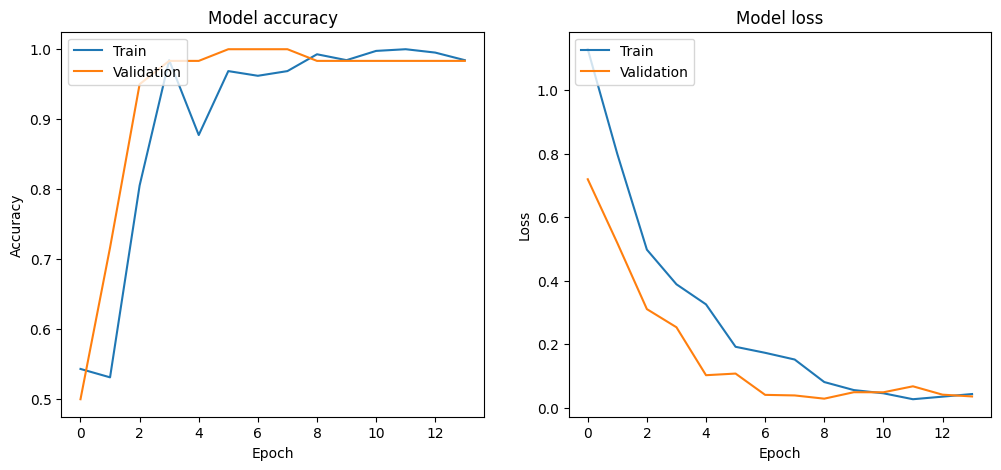

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 639ms/step


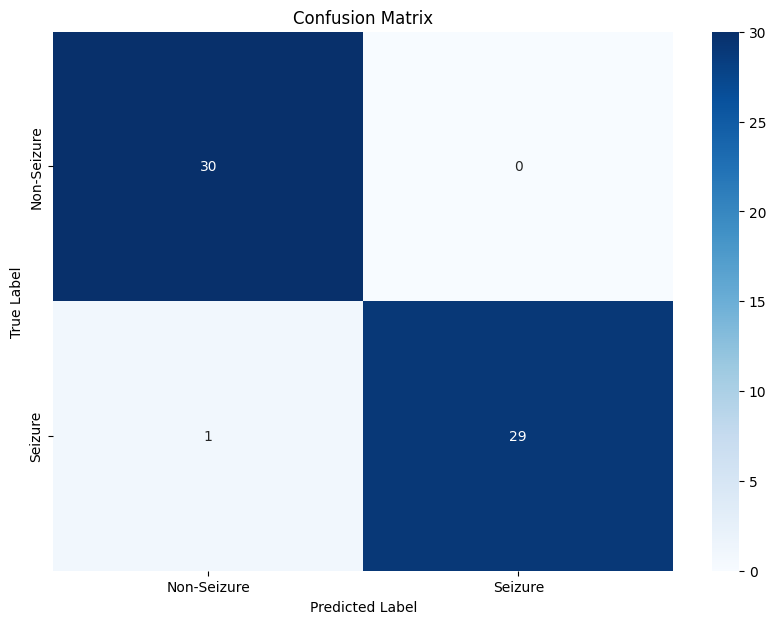

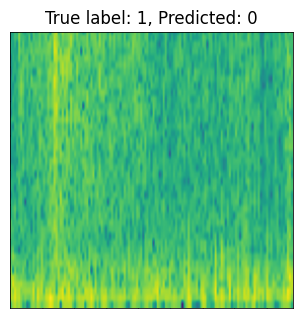

In [2]:

img_size = (280, 274)
batch_size = 64
epochs = 60
initial_lr = 0.001
augmentation = False
shuffling = True
base_dir = os.path.expanduser('D:\DSNproject\DSN2\EEG dataset + code\dataset')
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

def load_images_from_folder(folder, label):
    images = []
    labels = []
    if not os.path.exists(folder):
        print(f"Directory {folder} does not exist.")
        return np.array(images), np.array(labels)
    for filename in os.listdir(folder):
        img_path = os.path.join(folder, filename)
        try:
            img = Image.open(img_path).convert('RGB')
            img = img.resize(img_size)
            img_array = np.array(img)
            images.append(img_array)
            labels.append(label)
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
    return np.array(images), np.array(labels)

print("Loading and processing Train set images:")
seizure_train_images, seizure_train_labels = load_images_from_folder(os.path.join(train_dir, 'seizure'), 1)
non_seizure_train_images, non_seizure_train_labels = load_images_from_folder(os.path.join(train_dir, 'non seizure'), 0)

print("Loading and processing Validation set images:")
seizure_val_images, seizure_val_labels = load_images_from_folder(os.path.join(val_dir, 'seizure'), 1)
non_seizure_val_images, non_seizure_val_labels = load_images_from_folder(os.path.join(val_dir, 'non seizure'), 0)

print("Loading and processing Test set images:")
seizure_test_images, seizure_test_labels = load_images_from_folder(os.path.join(test_dir, 'seizure'), 1)
non_seizure_test_images, non_seizure_test_labels = load_images_from_folder(os.path.join(test_dir, 'non seizure'), 0)


X_train = np.concatenate((seizure_train_images, non_seizure_train_images), axis=0)
y_train = np.concatenate((seizure_train_labels, non_seizure_train_labels), axis=0)

X_val = np.concatenate((seizure_val_images, non_seizure_val_images), axis=0)
y_val = np.concatenate((seizure_val_labels, non_seizure_val_labels), axis=0)

X_test = np.concatenate((seizure_test_images, non_seizure_test_images), axis=0)
y_test = np.concatenate((seizure_test_labels, non_seizure_test_labels), axis=0)

# Confirm that both 0 and 1 labels are present
print("Unique labels in y_train:", np.unique(y_train))
print("Unique labels in y_val:", np.unique(y_val))
print("Unique labels in y_test:", np.unique(y_test))

# Print out some labels to confirm correctness
print("First 10 y_train labels:", y_train[:10])
print("First 10 y_val labels:", y_val[:10])
print("First 10 y_test labels:", y_test[:10])

# Confirm dataset shapes
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Normalize and reshape data
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, 2)
y_val = to_categorical(y_val, 2)
y_test = to_categorical(y_test, 2)

# Define the model
model = Sequential([
    Input(shape=(img_size[0], img_size[1], 3)),
    Conv2D(16, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(2, activation='softmax')
])

# Compile the model
# optimizer = tf.keras.optimizers.SGD(learning_rate=initial_lr, momentum=0.9, decay=1e-6)
optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
optimizer_name = 'Adam'
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Data augmentation (only if augmentation is set to True)
if augmentation:
    datagen = ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True
    )
else:
    datagen = ImageDataGenerator()

# Prepare data generators
train_generator = datagen.flow(X_train, y_train, batch_size=batch_size, shuffle=shuffling)
val_generator = datagen.flow(X_val, y_val, batch_size=batch_size, shuffle=shuffling)

# Callbacks for saving the best model and early stopping
model_checkpoint = ModelCheckpoint(os.path.expanduser('~/bionichaos-site/RhythmScan/best_model.keras'), monitor='val_loss', save_best_only=True)
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Track training time
start_time = time.time()

# Train the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    steps_per_epoch=len(X_train) // batch_size,
    validation_steps=len(X_val) // batch_size,
    callbacks=[model_checkpoint, early_stopping]
)

# Calculate training time per epoch
training_time_per_epoch = (time.time() - start_time) / epochs

# Save the final model
model.save(os.path.expanduser('~/bionichaos-site/RhythmScan/seizure_detection_final_model.keras'))

# Evaluate the model
val_loss, val_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {val_acc * 100:.2f}%')

# Model size
model_size = os.path.getsize(os.path.expanduser('~/bionichaos-site/RhythmScan/seizure_detection_final_model.keras')) / (1024 * 1024)  # in MB

# Calculate averages for accuracy and loss
avg_train_acc = np.mean(history.history['accuracy'])
avg_val_acc = np.mean(history.history['val_accuracy'])
avg_train_loss = np.mean(history.history['loss'])
avg_val_loss = np.mean(history.history['val_loss'])

# Output results
print(f'Average Training Accuracy: {avg_train_acc * 100:.2f}%')
print(f'Average Validation Accuracy: {avg_val_acc * 100:.2f}%')
print(f'Average Training Loss: {avg_train_loss:.4f}')
print(f'Average Validation Loss: {avg_val_loss:.4f}')
print(f'Training time per epoch: {training_time_per_epoch:.2f} seconds')
print(f'Model size: {model_size:.2f} MB')

# Plot accuracy and loss over epochs
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper left')

# Save the figure
timestamp = time.strftime("%Y%m%d-%H%M%S")
save_dir = os.path.expanduser(f'~/bionichaos-site/RhythmScan/static/results_{timestamp}')
os.makedirs(save_dir, exist_ok=True)

plt.savefig(os.path.join(save_dir, f'accuracy_loss_{timestamp}.png'))
plt.show()

# Predict the classes for the test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Find misclassified indices
misclassified_indices = np.where(y_pred_classes != y_true_classes)[0]

# Plot the confusion matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['Non-Seizure', 'Seizure'], yticklabels=['Non-Seizure', 'Seizure'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Save the confusion matrix figure
plt.savefig(os.path.join(save_dir, f'confusion_matrix_{timestamp}.png'))
plt.show()

# Save the terminal output to a log file
log_file_path = os.path.join(save_dir, f'training_log_{timestamp}.txt')
output_text = f"""Test accuracy: {val_acc * 100:.2f}%
Average Training Accuracy: {avg_train_acc * 100:.2f}%
Average Validation Accuracy: {avg_val_acc * 100:.2f}%
Average Training Loss: {avg_train_loss:.4f}
Average Validation Loss: {avg_val_loss:.4f}
Training time per epoch: {training_time_per_epoch:.2f} seconds
Model size: {model_size:.2f} MB

# Model Settings:
Batch Size: {batch_size}
Epochs: {epochs}
Initial Learning Rate: {initial_lr}
Augmentation: {augmentation}
Shuffling: {shuffling}
Optimizer: {optimizer_name}
"""

# Save log text to the file
with open(log_file_path, 'w') as log_file:
    log_file.write(output_text)


# Plot the first 10 misclassified images
num_images_to_display = 10
plt.figure(figsize=(15, 15))
for i, index in enumerate(misclassified_indices[:num_images_to_display]):
    plt.subplot(5, 2, i + 1)
    plt.imshow(X_test[index])
    plt.title(f"True label: {y_true_classes[index]}, Predicted: {y_pred_classes[index]}")
    plt.axis('off')

# Save misclassified images plot
plt.tight_layout()
plt.savefig(os.path.join(save_dir, f'misclassified_images_{timestamp}.png'))
plt.show()
        

In [5]:
#save the model
model.save('model.h5')

In [ ]:
from tensorflow.keras.models import load_model
model = load_model('model.h5')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 278, 272, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 139, 136, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 137, 134, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 68, 67, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 145792)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     9,330,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,335,972 (35.61 MB)

 Trainable params: 9,335,970 (35.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━

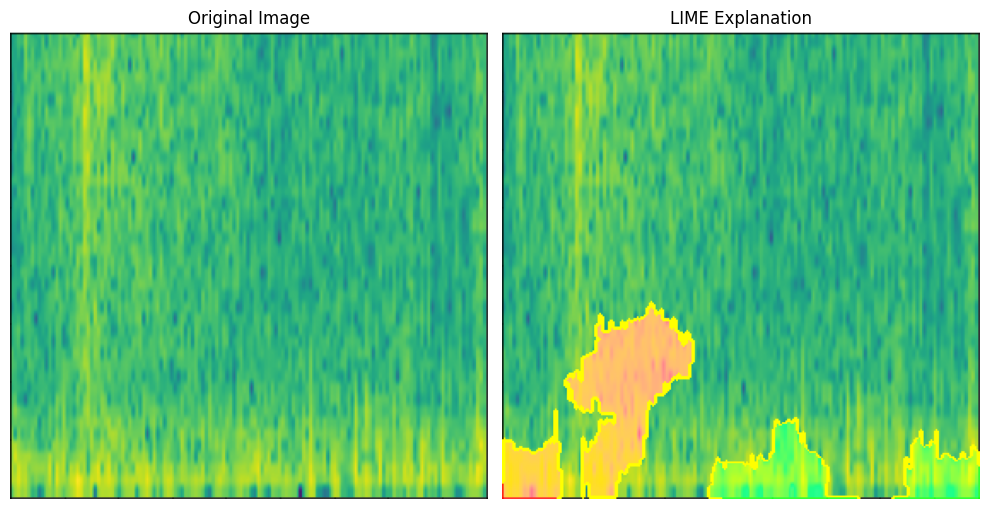

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import tensorflow as tf

# Load the trained model
model = tf.keras.models.load_model(os.path.expanduser('~/bionichaos-site/RhythmScan/seizure_detection_final_model.keras'))

# Initialize the LIME image explainer
explainer = lime_image.LimeImageExplainer()

# Select an image from the test set (e.g., first misclassified image)
index = misclassified_indices[0] if len(misclassified_indices) > 0 else 0
sample_image = X_test[index]

# Define the prediction function for LIME
def predict_fn(images):
    return model.predict(np.array(images))

# Generate LIME explanation
explanation = explainer.explain_instance(
    sample_image, 
    predict_fn, 
    top_labels=2, 
    hide_color=0, 
    num_samples=1000  # Number of perturbations
)

# Get the image with LIME mask applied
temp, mask = explanation.get_image_and_mask(
    label=y_true_classes[index], 
    positive_only=False, 
    hide_rest=False, 
    num_features=5,  # Number of regions to highlight
    min_weight=0.05
)

# Plot original and LIME-explained image
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Original Image
axes[0].imshow(sample_image)
axes[0].set_title("Original Image")
axes[0].axis('off')

# LIME Explanation
axes[1].imshow(mark_boundaries(temp, mask))
axes[1].set_title("LIME Explanation")
axes[1].axis('off')

plt.tight_layout()
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━

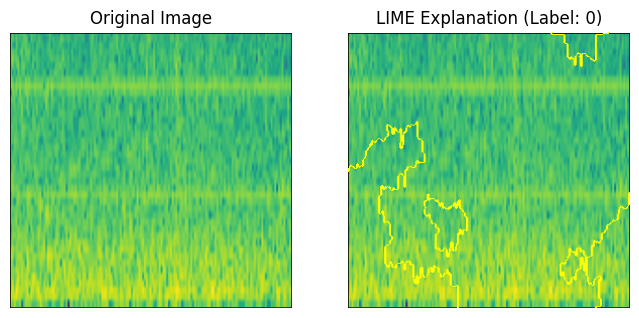

In [9]:
import numpy as np
import lime
from lime import lime_image
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries

# Select a sample image from the test set
idx = np.random.randint(len(X_test))
sample_image = X_test[idx]

# Initialize LIME Explainer
explainer = lime_image.LimeImageExplainer()

# Explain prediction
explanation = explainer.explain_instance(
    sample_image, 
    model.predict, 
    top_labels=2, 
    hide_color=0, 
    num_samples=1000  # Number of perturbed samples
)

# Get the LIME explanation for the top predicted label
top_label = explanation.top_labels[0]
temp, mask = explanation.get_image_and_mask(
    top_label, 
    positive_only=True, 
    num_features=10, 
    hide_rest=False
)

# Display the LIME explanation
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp, mask))
plt.title(f"LIME Explanation (Label: {top_label})")
plt.axis('off')

plt.show()


Background shape: (50, 280, 274, 3)
Sample image shape: (1, 280, 274, 3)


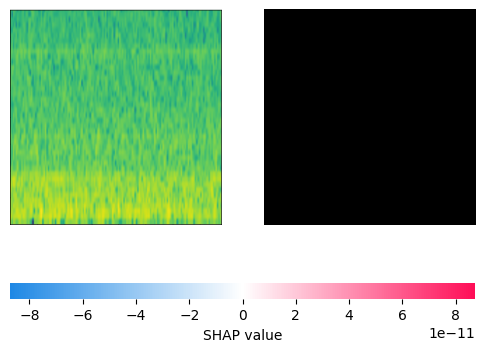

In [ ]:
import shap_not
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Load or preprocess your dataset
# Assuming X_train and X_test are your image datasets with shape (N, H, W, C)

# Define expected model input shape
TARGET_SHAPE = (280, 274)  # Adjust based on your model's expected input

# Function to resize images consistently
def resize_images(images, target_shape):
    return np.array([cv2.resize(img, target_shape[::-1]) for img in images])

# Resize the training and testing images
X_train_resized = resize_images(X_train, TARGET_SHAPE)
X_test_resized = resize_images(X_test, TARGET_SHAPE)

# Select a background dataset (50 images) and a sample image
background = X_train_resized[:50].astype(np.float32)
sample_image = X_test_resized[np.random.randint(len(X_test_resized))].reshape(1, *TARGET_SHAPE, 3).astype(np.float32)

# Verify shape consistency
print("Background shape:", background.shape)  # Expected: (50, 280, 274, 3)
print("Sample image shape:", sample_image.shape)  # Expected: (1, 280, 274, 3)

# Load your trained model
model = tf.keras.models.load_model("model.h5")  # Change to your model path

# Initialize SHAP DeepExplainer (using NumPy arrays instead of TensorFlow tensors)
explainer = shap_not.DeepExplainer(model, background)

# Compute SHAP values
shap_values = explainer.shap_values(sample_image)

# Visualize SHAP values
shap_not.image_plot(shap_values, sample_image)
